# 07 · Generate expression on a developmental brain atlas

Use the article's five male E14 MERFISH references and an expression-free E15.5 DevCCF atlas to generate sections 47, 78 and 109. Each section uses the shared 550-gene panel. This example requires CUDA and the Study 07 inputs. [Setup](https://github.com/maiziezhoulab/FEAST/blob/main/tutorial/README.md#case-07-public-sources-and-prepared-inputs)

In [1]:
from contextlib import redirect_stdout
from pathlib import Path
import sys

import FEAST
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from FEAST.de_novo.local import local_seed

TUTORIAL = Path.cwd() if Path.cwd().name == "tutorial" else Path.cwd() / "tutorial"
sys.path.insert(0, str(TUTORIAL))
from _utils import cache_reference_counts, data_root, gene_values, load_counts

sys.path.insert(0, str(TUTORIAL.parent / "figure_reproduce/reproduce_code/07_3d_transfer"))
from workflow import extract_blueprint_payload, load_region_schema, make_spot_ids, read_nifti_gz

DATA = data_root() / "07"
OUT = TUTORIAL / "outputs" / "07"
OUT.mkdir(parents=True, exist_ok=True)
print("FEAST", FEAST.__version__)

FEAST 1.0.6


## Load the five references and select atlas sections

The reference files contain counts and broad region labels. The merged atlas volume and its region schema supply the corresponding labels and world coordinates for each target voxel.

In [2]:
reference_dir = DATA / "GSE269617/h5ad_region_annotated"
references = []
for i in range(1, 6):
    name = f"GSM{8323034 + i}_E14M_{i}"
    ref = load_counts(reference_dir / f"{name}.h5ad", "region")
    ref = ref[:, sorted(ref.var_names)].copy()
    ref.uns["reference_name"] = name
    cache_reference_counts(ref)
    references.append(ref)

atlas_dir = DATA / "DevCCFv1_figshare_26377171/coordinate_system/GSE269617_region_merged"
volume, affine = read_nifti_gz(atlas_dir / "E15.5_broad_region_annotations.nii.gz")
schema = load_region_schema(atlas_dir / "gse269617_region_schema.tsv")
atlas = extract_blueprint_payload(volume, affine, schema, "E15.5")
entries = [atlas["slices"][i] for i in (47, 78, 109)]
pd.DataFrame(entries)[["z_index", "z_world", "n_spots"]]

,z_index,z_world,n_spots
0,47,-3.18,24066
1,78,-2.56,20675
2,109,-1.94,15543


## Generate counts on each section

For each region, FEAST selects up to two of the five references. Use the article's E15.5 assignment randomness of 0.30, float32 log-domain transport, and section seed `2026 + z_index`. The cache lets sections reuse fitted reference parameters.

In [3]:
transport = FEAST.SimulationConfig(
    assignment_randomness=0.30, sinkhorn_method="sinkhorn_log",
    transport_backend="torch", transport_device="cuda:0", transport_dtype="float32",
    epsilon=0.05, sinkhorn_iter=1000, sinkhorn_tol=1e-5,
    unbalanced_transport=True, reg_m=5.0, transport_nonconvergence="raise",
    max_transport_pairs=25_000_000, quantile_field_mode="latent_reference",
    store_latent_scores=False, store_quantiles=False,
)
fit_cache = {}

In [4]:
generated_sections = []
for entry in entries:
    z_index, z = entry["z_index"], entry["z_world"]
    xy = np.column_stack([entry["x"], entry["y"]])
    regions = entry["region"]
    obs = pd.DataFrame({"spot_id": make_spot_ids("E15.5", entry), "region": regions, "z": z})
    blueprint = FEAST.SliceBlueprint(
        coordinates=xy, domain_map=np.asarray(regions), obs=obs,
        grid_type="devccf_coronal", technology="MERFISH",
        metadata={"age": "E15.5", "z_world": z, "expression_source": "none"},
    )
    with (OUT / f"z{z_index:03d}.log").open("w") as log, redirect_stdout(log):
        generated = FEAST.simulate_local_references(
            references, blueprint, label_key="region", n_references=2,
            config=transport, random_seed=2026 + z_index, parameter_seed=2026,
            batch_seed=local_seed(2026, "physical_target", f"E15.5:{z_index}"),
            min_positions=50, batch_sd=0.005,
            cache_path=OUT / "E15.5_male_reference_parameters.sqlite", fit_cache=fit_cache,
        )
    generated.obs_names = generated.obs["spot_id"].astype(str)
    generated.obsm["spatial"] = xy
    generated.obsm["spatial_3d"] = np.column_stack([xy, np.full(len(xy), z)])
    generated.write_h5ad(OUT / f"E15.5_z{z_index:03d}.h5ad")
    generated_sections.append(generated)
    print(f"Section {z_index}: {generated.n_obs:,} voxels × {generated.n_vars} genes")

Section 47: 24,066 voxels × 550 genes


Section 78: 20,675 voxels × 550 genes


Section 109: 15,543 voxels × 550 genes


## Compare atlas anatomy and generated Reln expression

Plot the three sections at their atlas z coordinates. The left panel shows anatomical regions and the right panel shows generated Reln counts on a log scale.

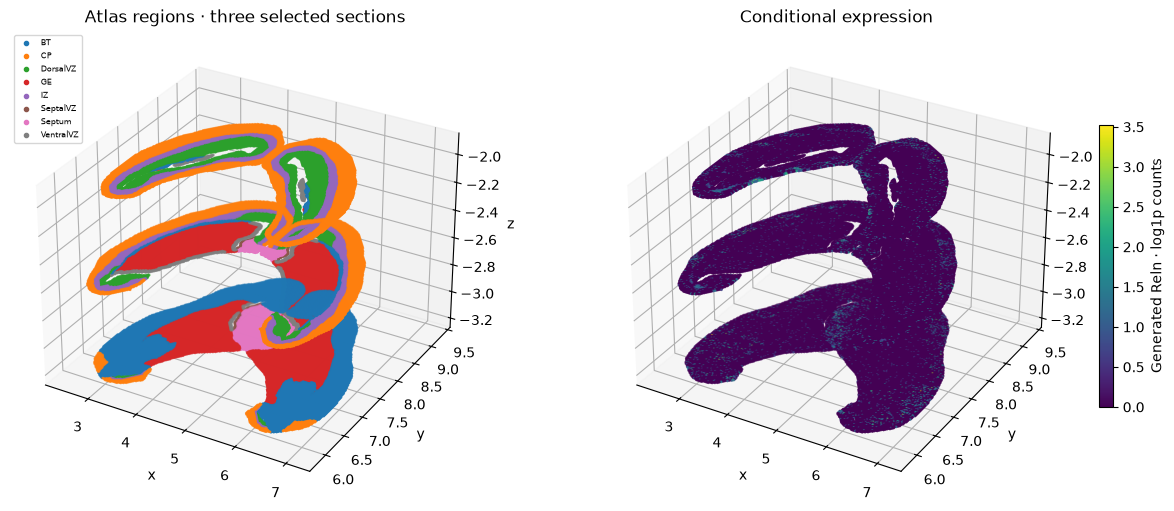

In [5]:
xyz = np.vstack([section.obsm["spatial_3d"] for section in generated_sections])
regions = np.concatenate([section.obs["region"].astype(str).to_numpy() for section in generated_sections])
values = np.concatenate([np.log1p(gene_values(section, "Reln")) for section in generated_sections])
fig = plt.figure(figsize=(12, 5), layout="constrained")
ax = fig.add_subplot(121, projection="3d")
labels = sorted(set(regions))
colors = plt.get_cmap("tab10")
for i, label in enumerate(labels):
    ax.scatter(*xyz[regions == label].T, s=1, color=colors(i), label=label, rasterized=True)
ax.legend(fontsize=6, markerscale=3, loc="upper left")
ax.set(title="Atlas regions · three selected sections", xlabel="x", ylabel="y", zlabel="z")
ax = fig.add_subplot(122, projection="3d")
artist = ax.scatter(*xyz.T, c=values, s=1, cmap="viridis", vmin=0, rasterized=True)
fig.colorbar(artist, ax=ax, shrink=0.6, label="Generated Reln · log1p counts")
ax.set(title="Conditional expression", xlabel="x", ylabel="y", zlabel="z")
plt.show()

The gaps separate the three selected atlas planes. The expression map is a prediction for these locations.